# Bloque 3: Comparaciones y tests

En este bloque contrastamos hipótesis sobre los conteos. Como conocemos cómo se generan los datos, además de aplicar cada test una vez vamos a estimar por simulación con qué frecuencia rechaza: si $H_0$ es verdadera, esa proporción estima el **nivel** del test; si es falsa, estima su **potencia**.

Todos los tests pueden calcularse con `scipy.stats`; no es necesario programar los estadísticos a mano. Como la proporción de rechazos se estima varias veces, conviene escribir una única función, por ejemplo `proporcion_rechazos(generar_par, test, R)`, que llame $R$ veces a `generar_par()` (que devuelve un par de muestras nuevas), aplique `test` a cada par y devuelva la proporción de $p$-valores menores que 0,05.

---

## Setup

In [1]:
# Imports
import json
import numpy as np
import pandas as pd
from codigo_base import *
import scipy.stats as stats
import matplotlib.pyplot as plt

# Estilo de los gráficos
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e4e3df",
    "grid.linewidth": 0.6,
    "axes.edgecolor": "#8a8984",
    "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
    "axes.titlesize": 11,
    "lines.linewidth": 2,
    "legend.frameon": False,
    "legend.fontsize": 9,
})
AZUL, NARANJA, GRIS = "#2a78d6", "#eb6834", "#52514e"

# Variables globales
rng = np.random.default_rng(4)

# Datos: una medición por renglón
df = pd.read_json("conteos.jsonl", lines=True)
df.head()

,experimento,algoritmo,n,k,lista,swaps,comparaciones
0,uniforme,insertion,100,NaN,0,2304,2398
1,uniforme,selection,100,NaN,0,94,4950
2,uniforme,quick_primero,100,NaN,0,373,604
3,uniforme,quick_medio,100,NaN,0,351,635
4,uniforme,insertion,100,NaN,1,2447,2543


### Datos del experimento `uniforme`

Arrays `S` (swaps de insertion sort) y `Q` (comparaciones de quicksort con pivote en el primer elemento), ordenados por `lista`.

In [2]:
uniforme = df[df["experimento"] == "uniforme"]

S = (uniforme[uniforme["algoritmo"] == "insertion"]
     .sort_values("lista")["swaps"].to_numpy())
Q = (uniforme[uniforme["algoritmo"] == "quick_primero"]
     .sort_values("lista")["comparaciones"].to_numpy())

print(f"len(S) = {len(S)}, media = {S.mean():.2f}  (teórica: {100*99/4:.2f})")
print(f"len(Q) = {len(Q)}, media = {Q.mean():.2f}  (teórica: 647.85)")

len(S) = 2000, media = 2470.13  (teórica: 2475.00)
len(Q) = 2000, media = 645.28  (teórica: 647.85)


---

## Herramientas

- **Test de Shapiro–Wilk** (`scipy.stats.shapiro`). $H_0$: los datos son una muestra de alguna distribución normal, con media y varianza no especificadas. No lo vimos en clase: forma parte del trabajo investigarlo.
- **Test $t$ de Welch** (`scipy.stats.ttest_ind` con `equal_var=False`). $H_0$: $\mu_X = \mu_Y$, sin suponer que las dos varianzas son iguales. Usa el estadístico
$$T = \frac{\bar X - \bar Y}{\sqrt{s_X^2/N_X + s_Y^2/N_Y}},$$
que bajo $H_0$ tiene distribución aproximadamente $t$, con grados de libertad estimados a partir de los datos.
- **Test de permutaciones** (para el ítem optativo 3.2 d). $H_0$: las dos muestras provienen de la misma distribución. Si $H_0$ es cierta, la etiqueta de cada observación (a qué muestra pertenece) no importa. Se juntan las $N_X + N_Y$ observaciones, se las reparte al azar en dos grupos de tamaños $N_X$ y $N_Y$, se recalcula la diferencia de medias, y se repite esto $B$ veces. El $p$-valor es la proporción de repartos en los que la diferencia, en valor absoluto, es al menos tan grande como la observada. Puede programarse a mano o con `scipy.stats.permutation_test`.
- **Intervalo bootstrap percentil** (para el ítem 3.5). Para un estadístico $\hat\theta$ calculado a partir de una muestra: se generan $B$ muestras bootstrap, cada una tomando $N$ valores con reposición de la muestra original; se calcula $\hat\theta$ en cada una, y el intervalo de nivel 0,95 va del percentil 2,5 al percentil 97,5 de esos $B$ valores (`scipy.stats.bootstrap` con `method="percentile"`).

---

## Función auxiliar: `proporcion_rechazos`

`proporcion_rechazos(generar_par, test, R)`: llama $R$ veces a `generar_par()`, aplica `test` a cada par y devuelve la proporción de $p$-valores menores que 0,05.

In [3]:
def proporcion_rechazos(generar_par, test, R, alfa=0.05):
    """Llama R veces a generar_par(), aplica test a cada par de muestras
    y devuelve la proporción de p-valores menores que alfa."""
    pvalores = np.array([test(*generar_par()) for _ in range(R)])
    return np.mean(pvalores < alfa)

---

## Ejercicio 3.1: Normalidad

### 3.1 a)

Investigue el test de Shapiro–Wilk: qué compara su estadístico y qué valores llevan a rechazar $H_0$. ¿Qué relación tiene con el gráfico cuantil-cuantil contra la normal?

--- 

El test de Shapiro–Wilk es para evaluar si una muestra proviene de una población con distribución normal.

$$
W = \frac{\left(\displaystyle\sum_{i=1}^{N} a_i\, x_{(i)}\right)^2}{\displaystyle\sum_{i=1}^{N} (x_i - \bar{x})^2}
$$



Su estadístico $W$ compara dos estimaciones de la varianza de la muestra, una basada en datos ordenados y en los valores esperados de una distribución normal (el numerador) y la otra es la varianza muestral habitual (el denominador). Si los datos son normales, ambas estimaciones son similares. 
Esto significa que el estadístico $W$ del test toma valores entre 0 y 1. Valores cercanos a 0 indican que los datos no pertenecen a una distribución normal. Por eso se rechaza $H_0$ cuando $W$ es chico, que es lo mismo que un p-valor chico ($p < 0,05$).


#### Cómo se arma un QQ-plot contra la normal:
1. Ordenás tus datos de menor a mayor: $x_{(1)} \le x_{(2)} \le \dots \le x_{(N)}$. El dato $x_{(i)}$ es el cuantil empírico de orden aproximadamente $i/N$ de tu muestra.
2. Para cada $i$ calculás el cuantil de una $N(0,1)$ con esa misma proporción, aproximadamente $m_i = \Phi^{-1}\left(\frac{i-0.5}{N}\right)$. Es el valor que "debería" ocupar el puesto $i$ si los datos fueran normales estándar.
3. Graficás los puntos $(m_i,\ x_{(i)})$: en el eje x los cuantiles teóricos y en el eje y tus datos ordenados.

Entonces cada eje responde una pregunta distinta sobre el mismo puesto $i$:
- Eje X ($m_i$): dónde estaría el $i$-ésimo más chico si los datos fueran $N(0,1)$. Depende solo de $i$ y $N$; no de los datos.
- Eje Y ($x_{(i)}$): dónde está de verdad el $i$-ésimo más chico en los datos.

#### Relación QQ-plot y Test Shapiro-Wilk

Si los datos son normales, los puntos $(m_i,\ x_{(i)})$ del QQ-plot quedan sobre una recta de ordenada $\mu$ y pendiente $\sigma$, porque una $N(\mu, \sigma^2)$ es una $N(0,1)$ corrida en $\mu$ y estirada por $\sigma$. Si los datos no son normales, los puntos se curvan.

El estadístico $W$ mide qué tan recto es el QQ-plot. Es aproximadamente el cuadrado de la correlación entre los cuantiles teóricos $m_i$ y los datos ordenados $x_{(i)}$: vale 1 si los puntos están perfectamente alineados y baja a medida que se curvan. Por ejemplo, con 200 datos simulados de una normal el $r^2$ del QQ-plot da $0{,}992$ y $W = 0{,}989$, y con 200 datos de una exponencial $r^2 = 0{,}776$ y $W = 0{,}782$.

Con datos normales los puntos igual oscilan un poco alrededor de la recta por azar, así que $W$ queda un poco por debajo de 1. El p-valor mide qué tan probable es obtener un $W$ así de chico si los datos fueran normales. Si es menor a $0{,}05$ se rechaza $H_0$.

Los dos se complementan: el QQ-plot muestra cómo se apartan los datos de la normal (asimetría, colas pesadas), y el test dice si ese apartamiento es más grande de lo que explicaría el azar.

---

### 3.1 b)

Aplíquelo a $S_{100}$ y a $Q_{100}$ usando las primeras $N = 50, 200, 1000$ y $2000$ listas del experimento `uniforme`, junto con gráficos cuantil-cuantil. ¿Cómo cambian los $p$-valores con $N$ en cada caso?

---

In [4]:
Ns = [50, 200, 1000, 2000]
variables = {"S_100": S, "Q_100": Q}

# Shapiro–Wilk sobre las primeras N listas de cada variable
resultados = {}
for nombre, datos in variables.items():
    for N in Ns:
        W, p = stats.shapiro(datos[:N])
        resultados[(nombre, N)] = (W, p)

tabla = pd.DataFrame(
    {(nombre, col): [resultados[(nombre, N)][j] for N in Ns]
     for nombre in variables for j, col in enumerate(["W", "p-valor"])},
    index=pd.Index(Ns, name="N"),
)
# W con 4 decimales; p-valor en notación científica (los de Q son muy chicos)
tabla.apply(lambda col: col.map("{:.4f}".format if col.name[1] == "W" else "{:.2e}".format))

S_100             Q_100          
           W   p-valor       W   p-valor
N                                       
50    0.9840  7.30e-01  0.9401  1.36e-02
200   0.9928  4.37e-01  0.9662  9.77e-05
1000  0.9985  5.56e-01  0.9550  5.95e-17
2000  0.9993  6.68e-01  0.9607  7.35e-23

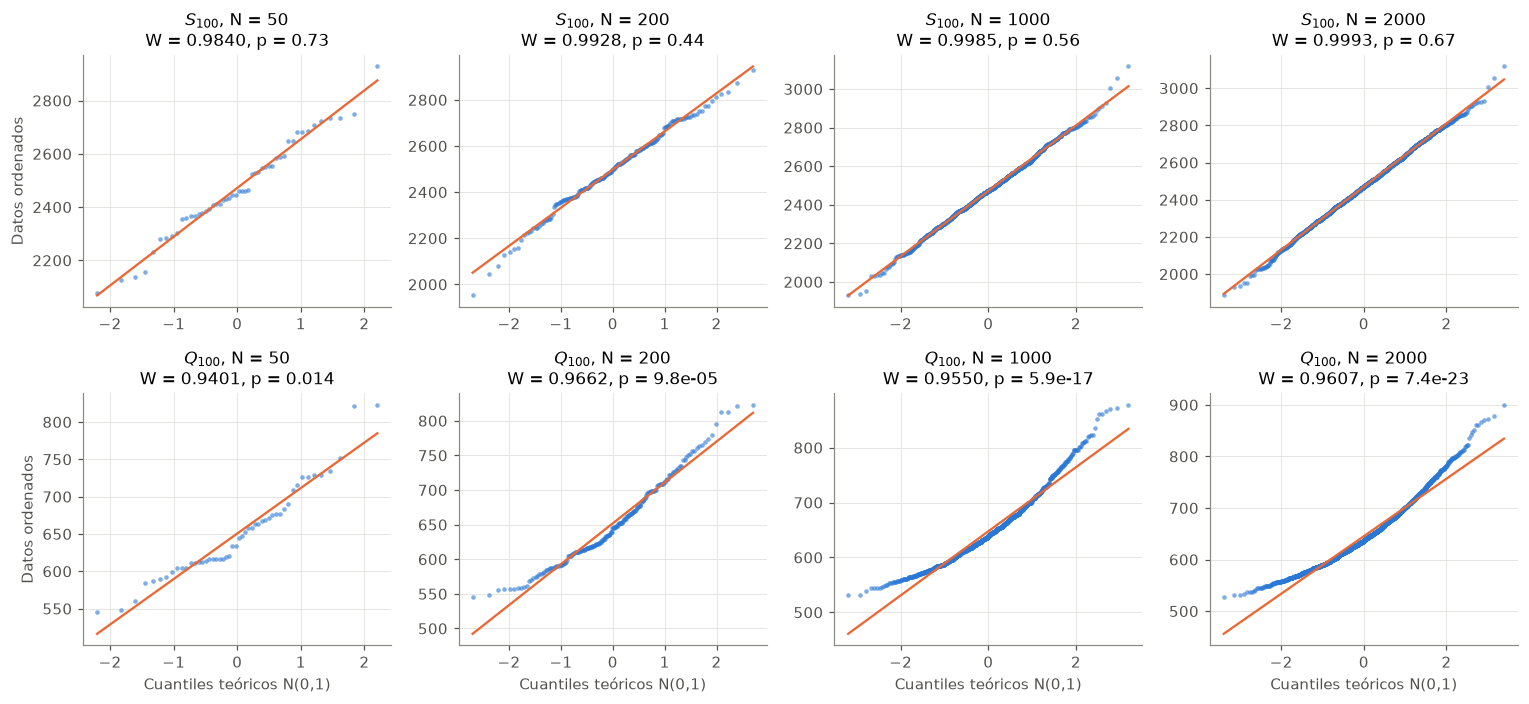

In [5]:
fig, axes = plt.subplots(2, len(Ns), figsize=(14, 6.5))

for fila, (nombre, datos) in enumerate(variables.items()):
    etiqueta = nombre.replace("_100", "_{100}")
    for col, N in enumerate(Ns):
        ax = axes[fila, col]
        stats.probplot(datos[:N], dist="norm", plot=ax)
        puntos, recta = ax.get_lines()
        puntos.set(color=AZUL, markersize=3, alpha=0.6, markeredgewidth=0)
        recta.set(color=NARANJA, linewidth=1.5)

        W, p = resultados[(nombre, N)]
        ax.set_title(f"${etiqueta}$, N = {N}\nW = {W:.4f}, p = {p:.2g}")
        ax.set_xlabel("Cuantiles teóricos N(0,1)" if fila == 1 else "")
        ax.set_ylabel("Datos ordenados" if col == 0 else "")

plt.tight_layout()
plt.show()

El QQ Plot es consistente con el del ejercicio 1.2. Muestra que $Q_{100}$ tiene una distribución asimétrica a derecha: en los dos extremos los puntos quedan por encima de la recta, o sea que la cola derecha es larga y la izquierda es corta. Coincide con el $\hat{\gamma}_Q \approx 0{,}83$ positivo del 1.2.

El p-valor en $Q_{100}$ es muy chico para todos los $N$, lo cual significa que se rechaza $H_0$. Tiene sentido porque $Q$ es asimétrica. Además el p-valor baja mucho a medida que crece $N$ (de $0{,}014$ con $N = 50$ a $7 \cdot 10^{-23}$ con $N = 2000$), mientras que $W$ se mantiene parecido (entre $0{,}94$ y $0{,}97$).

Por otro lado $S_{100}$ tiene p-valores grandes para todos los $N$ y sin ninguna tendencia: suben y bajan al azar. El test nunca rechaza, lo cual significa que los datos son compatibles con una normal.

A medida que aumentamos $N$ el test se vuelve más sensible, porque con más datos el QQ-plot de una normal oscila menos y $W$ queda más cerca de 1. Por eso el mismo desvío de $Q$ se detecta cada vez con más claridad, mientras que en $S$ no aparece ningún desvío y el p-valor se mueve al azar.

---

### 3.1 c)

Un único $p$-valor con $N$ chico cambia mucho de una muestra a otra. Para $N = 50$, divida las 2000 listas en 40 bloques disjuntos y calcule, para $S_{100}$ y para $Q_{100}$, en qué proporción de ellos el test rechaza al nivel 0,05. ¿Qué estima cada proporción? $S_{100}$ no es exactamente normal: toma valores enteros entre 0 y 4950. ¿Por qué el test casi nunca lo detecta? ¿Se puede concluir de un no rechazo que los datos son normales? (Ayuda: recuerde la definición de potencia.)

---

In [6]:
N_bloque, n_bloques = 50, 40

# p-valores de Shapiro–Wilk en cada bloque disjunto de 50 listas
pvalores = {
    nombre: np.array([stats.shapiro(bloque)[1] for bloque in datos.reshape(n_bloques, N_bloque)])
    for nombre, datos in variables.items()
}

for nombre, p in pvalores.items():
    print(f"{nombre}: rechaza en {np.sum(p < 0.05):2d} de {n_bloques} bloques  ->  proporción = {np.mean(p < 0.05):.3f}")

S_100: rechaza en  4 de 40 bloques  ->  proporción = 0.100
Q_100: rechaza en 24 de 40 bloques  ->  proporción = 0.600


Distribución de los 40 p-valores de cada variable. La línea punteada marca el nivel 0,05: los bloques a su izquierda son los que rechazan.

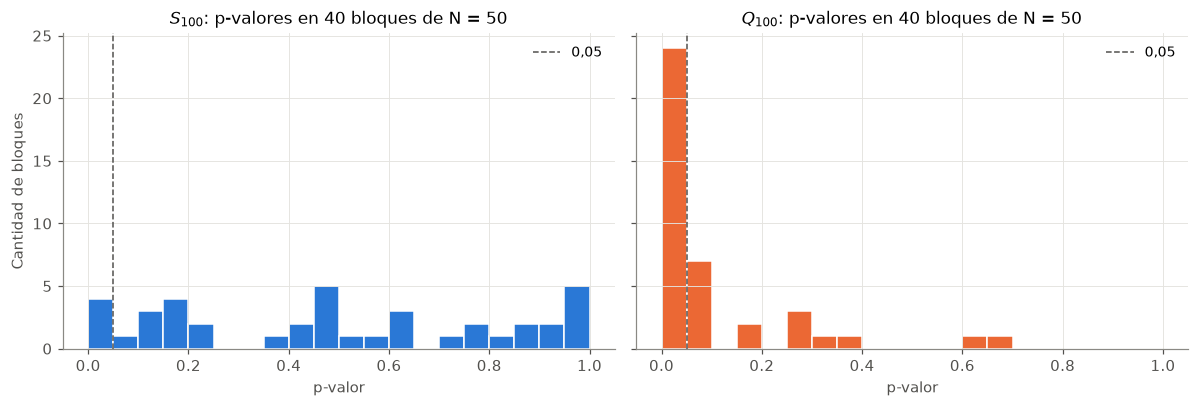

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
bordes = np.linspace(0, 1, 21)

for ax, (nombre, p), color in zip(axes, pvalores.items(), [AZUL, NARANJA]):
    etiqueta = nombre.replace("_100", "_{100}")
    ax.hist(p, bins=bordes, color=color, edgecolor="white")
    ax.axvline(0.05, color=GRIS, linestyle="--", linewidth=1, label="0,05")
    ax.set_title(f"${etiqueta}$: p-valores en {n_bloques} bloques de N = {N_bloque}")
    ax.set_xlabel("p-valor")
    ax.legend()
axes[0].set_ylabel("Cantidad de bloques")
plt.tight_layout()
plt.show()

Escala de $S_{100}$, para comparar el tamaño de los escalones (valores enteros) y de los límites $0$ y $4950$ con su desvío.

In [8]:
# Escala de S_100: desvío teórico y a cuántos desvíos están los extremos posibles
n = 100
mu_S = n * (n - 1) / 4
sigma_S = np.sqrt(n * (n - 1) * (2 * n + 5) / 72)
print(f"mu_S = {mu_S:.0f},  sigma_S = {sigma_S:.1f}")
print(f"Un escalón de 1 equivale a {1 / sigma_S:.4f} desvíos")
print(f"El 0 está a {(0 - mu_S) / sigma_S:.1f} desvíos de la media y el 4950 a {(4950 - mu_S) / sigma_S:.1f}")
print(f"P(|Z| > {mu_S / sigma_S:.1f}) para una normal = {2 * stats.norm.sf(mu_S / sigma_S):.1e}")

mu_S = 2475,  sigma_S = 167.9
Un escalón de 1 equivale a 0.0060 desvíos
El 0 está a -14.7 desvíos de la media y el 4950 a 14.7
P(|Z| > 14.7) para una normal = 3.5e-49


Cada bloque es una muestra independiente de 50 listas, así que la proporción de bloques en los que el test rechaza estima la probabilidad de que el test rechace con $N = 50$. Si $H_0$ es verdadera esa probabilidad es el nivel del test, y si $H_0$ es falsa es su potencia.

Para $Q_{100}$ el test rechaza en 24 de los 40 bloques (proporción $0{,}60$). Como $Q$ es asimétrica, $H_0$ es falsa, lo cual significa que $0{,}60$ estima la potencia del test con $N = 50$ para detectar que $Q_{100}$ no es normal. En 4 de cada 10 muestras el test no lo detecta (error de tipo II). Tiene sentido con el ítem b): con $N$ chico el test tiene menos potencia, y con $N$ grande rechazaba siempre.

Por otro lado $S_{100}$ rechaza en 4 de los 40 bloques (proporción $0{,}10$). Si $S_{100}$ fuera normal, esa proporción estimaría el nivel, que vale $0{,}05$. La diferencia entre $0{,}10$ y $0{,}05$ se explica por el azar de tener solo 40 bloques: si la probabilidad de rechazo fuera $0{,}05$, la cantidad de rechazos sería $\text{Binomial}(40;\ 0{,}05)$, con 2 rechazos esperados, y obtener 4 o más pasa con probabilidad $\approx 0{,}14$. Además el histograma muestra los p-valores repartidos de forma pareja entre 0 y 1, como pasa cuando $H_0$ es verdadera.

$S_{100}$ toma valores enteros entre 0 y 4950, así que estrictamente $H_0$ es falsa y la proporción también estima una potencia. El test casi nunca lo detecta porque la diferencia con una normal es muy chica comparada con su desvío $\sigma_S \approx 167{,}9$: un escalón de 1 equivale a $0{,}006$ desvíos, y los límites 0 y 4950 están a $14{,}7$ desvíos de la media, donde una normal tiene probabilidad $\approx 10^{-49}$. Con 50 datos el test ve a $S_{100}$ igual que a una normal, y su potencia queda prácticamente igual al nivel.

Por eso de un no rechazo no se puede concluir que los datos sean normales. La potencia del test contra esta diferencia es casi $0{,}05$, lo cual significa que el test no rechaza en el 95% de los casos aunque $H_0$ sea falsa. Un no rechazo solo dice que la diferencia con una normal, si existe, es demasiado chica para detectarla con esos datos.

---

## Ejercicio 3.2: Nivel y potencia: el efecto del desorden

Compare las comparaciones de quicksort $Q_{100}$ sobre permutaciones uniformes de 100 elementos con las obtenidas sobre listas de 100 elementos con desorden $k$, usando $N = 50$ listas nuevas de cada tipo y $R = 300$ repeticiones.

Funciones para este ejercicio: `generar_Q(N, k)` genera $N$ listas **nuevas** de 100 elementos (uniformes si `k=None`, con desorden $k$ si no) y devuelve las comparaciones de quicksort con pivote en el primer elemento; `welch(x, y)` devuelve el $p$-valor del test de Welch.

In [9]:
def generar_Q(N, k=None, n=100):
    """Comparaciones de quicksort (pivote = primero) sobre N listas nuevas de tamaño n.
    k=None: permutaciones uniformes; k entero: lista ordenada con k transposiciones al azar."""
    comps = np.empty(N, dtype=int)
    for r in range(N):
        lista = permutacion_aleatoria(n, rng) if k is None else lista_desordenada(n, k, rng)
        comps[r] = quicksort(lista, "primero")[1]
    return comps


def welch(x, y):
    """p-valor del test t de Welch (no supone varianzas iguales)."""
    return stats.ttest_ind(x, y, equal_var=False).pvalue


N, R = 50, 300

### 3.2 a)

**Nivel.** Compare dos muestras independientes de permutaciones uniformes con un test de Welch y estime la proporción de rechazos. ¿Qué cantidad está estimando y cuánto debería valer? (Ayuda: recuerde que el nivel es la probabilidad de rechazar $H_0$ cuando $H_0$ es verdadera, es decir, de cometer un error de tipo I; la potencia es la probabilidad de rechazar $H_0$ cuando $H_1$ es verdadera, es decir, $1 - P(\text{error de tipo II})$.)

---

In [10]:
# Las dos muestras son de permutaciones uniformes: H0 es verdadera
nivel = proporcion_rechazos(lambda: (generar_Q(N), generar_Q(N)), welch, R)
ee = np.sqrt(0.05 * 0.95 / R)   # error estándar de la proporción si el nivel real fuera 0,05

print(f"Proporción de rechazos (H0 verdadera): {nivel:.3f}")
print(f"Si el nivel fuera 0,05, la proporción estaría en 0,05 ± {1.96 * ee:.3f} el 95% de las veces")

Proporción de rechazos (H0 verdadera): 0.047
Si el nivel fuera 0,05, la proporción estaría en 0,05 ± 0.025 el 95% de las veces


Como $H_0$ es verdadera, la proporción de rechazos estima el nivel del test, es decir la probabilidad de cometer un error de tipo I. Debería valer $0{,}05$, que es el nivel que elegimos. Obtuvimos $0{,}047$, que es compatible con $0{,}05$: con $R = 300$ repeticiones, si el nivel real fuera $0{,}05$ la proporción estaría en $0{,}05 \pm 0{,}025$ el 95% de las veces.

---

### 3.2 b)

**Potencia.** Para $k = 50, 75, 100, 125, 150, 200, 300$, estime la proporción de rechazos del test de Welch y grafíquela en función de $k$.

---

In [11]:
ks = [50, 75, 100, 125, 150, 200, 300]

# Uniformes contra desorden k: proporción de rechazos del test de Welch para cada k
potencia = {k: proporcion_rechazos(lambda: (generar_Q(N), generar_Q(N, k)), welch, R) for k in ks}

for k, p in potencia.items():
    print(f"k = {k:3d}: proporción de rechazos = {p:.3f}")

k =  50: proporción de rechazos = 1.000
k =  75: proporción de rechazos = 0.963
k = 100: proporción de rechazos = 0.563
k = 125: proporción de rechazos = 0.223
k = 150: proporción de rechazos = 0.100
k = 200: proporción de rechazos = 0.067
k = 300: proporción de rechazos = 0.070


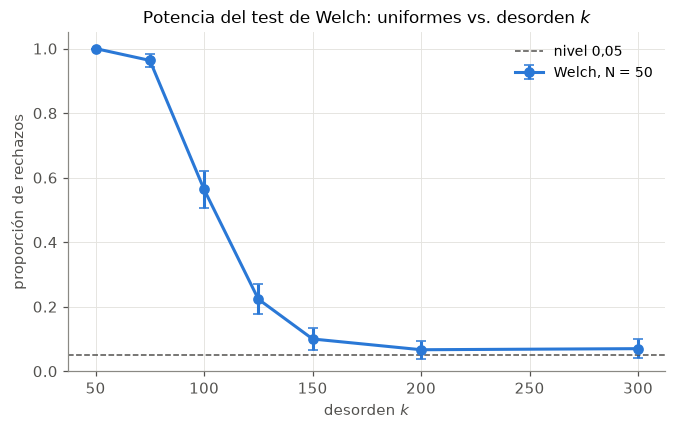

In [12]:
p = np.array(list(potencia.values()))
ee_p = np.sqrt(p * (1 - p) / R)

fig, ax = plt.subplots(figsize=(7, 4))
ax.errorbar(ks, p, yerr=1.96 * ee_p, marker="o", color=AZUL, capsize=3, label="Welch, N = 50")
ax.axhline(0.05, color=GRIS, linestyle="--", linewidth=1, label="nivel 0,05")
ax.set_xlabel("desorden $k$")
ax.set_ylabel("proporción de rechazos")
ax.set_title("Potencia del test de Welch: uniformes vs. desorden $k$")
ax.set_ylim(0, 1.05)
ax.legend()
plt.show()

Como referencia, media, desvío y mediana de $Q_{100}$ para cada $k$ en el experimento `desorden` (300 listas por $k$), junto con $\mu_Q$ de las permutaciones uniformes.

In [13]:
desorden_Q = df[(df["experimento"] == "desorden") & (df["algoritmo"] == "quick_primero")]
resumen_k = desorden_Q.groupby("k")["comparaciones"].agg(["mean", "std", "median"]).round(1)
resumen_k.index = resumen_k.index.astype(int)

H = np.sum(1 / np.arange(1, 101))
mu_Q = 2 * 101 * H - 4 * 100
print(f"mu_Q (uniformes, teórica) = {mu_Q:.2f}")
resumen_k

mu_Q (uniformes, teórica) = 647.85


,mean,std,median
k,,,
0,4950.0,0.0,4950.0
5,2376.4,672.0,2333.5
10,1613.1,521.1,1520.0
25,968.6,229.0,916.5
50,774.1,130.9,753.0
100,673.5,74.3,661.0
150,660.0,71.8,646.0
200,648.3,57.3,640.5
300,651.4,64.7,640.0


Con $k = 50$ el test rechaza siempre y con $k = 75$ casi siempre ($0{,}963$). Entre $k = 75$ y $k = 150$ la proporción de rechazos cae mucho, y a partir de $k = 150$–$200$ queda cerca de $0{,}05$.

Tiene sentido porque con pocas transposiciones la lista queda casi ordenada, y quicksort con pivote en el primer elemento hace muchas comparaciones (con $k = 0$ hace $4950$). A medida que $k$ crece la lista se parece cada vez más a una permutación uniforme, y la media de $Q_{100}$ se acerca a $\mu_Q = 647{,}85$ ($774{,}1$ con $k = 50$, $673{,}5$ con $k = 100$, $648{,}3$ con $k = 200$).

La potencia depende de qué tan grande es la diferencia de medias comparada con el denominador del estadístico de Welch, $\sqrt{s_X^2/N + s_Y^2/N}$. Con $k = 50$ la diferencia es de unas 126 comparaciones y el denominador es $\approx 20$, así que $T$ es muy grande y el test rechaza siempre. Con $k = 100$ la diferencia es de unas 26 comparaciones y el denominador $\approx 14$, así que $T$ queda cerca de $1{,}96$ y el test rechaza más o menos la mitad de las veces.

---

### 3.2 c)

¿A partir de qué $k$ deja de detectarse una diferencia? Que el test no rechace, ¿significa que las dos distribuciones son iguales? Para $k = 200$, estime la proporción de rechazos con $N = 5000$ listas de cada tipo ($R = 100$ repeticiones alcanzan) y compárela con la que obtuvo con $N = 50$.

---

In [14]:
# k = 200 con muestras mucho más grandes (tarda unos 3-4 minutos)
N_grande, R_grande = 5000, 100
pot_200_grande = proporcion_rechazos(lambda: (generar_Q(N_grande), generar_Q(N_grande, 200)), welch, R_grande)

print(f"k = 200, N = {N:4d} (R = {R}): proporción de rechazos = {potencia[200]:.3f}")
print(f"k = 200, N = {N_grande} (R = {R_grande}): proporción de rechazos = {pot_200_grande:.3f}")

k = 200, N =   50 (R = 300): proporción de rechazos = 0.067
k = 200, N = 5000 (R = 100): proporción de rechazos = 0.740


Para entender la diferencia entre $N = 50$ y $N = 5000$, estimamos con muchas listas la diferencia real entre $\mathrm{E}(Q_{100} \mid k = 200)$ y $\mu_Q$, y la comparamos con el denominador del estadístico de Welch para cada $N$.

In [15]:
# Diferencia real de medias con k = 200, estimada con muchas listas (tarda ~15 s)
Q_200 = generar_Q(50_000, 200)
H2 = np.sum(1 / np.arange(1, 101) ** 2)
sigma_Q = np.sqrt(7 * 100**2 - 4 * 101**2 * H2 - 2 * 101 * H + 13 * 100)

dif = Q_200.mean() - mu_Q
print(f"E(Q | k=200) ≈ {Q_200.mean():.2f} ± {1.96 * Q_200.std(ddof=1) / np.sqrt(len(Q_200)):.2f}   (mu_Q = {mu_Q:.2f})")
print(f"Diferencia real ≈ {dif:.2f} comparaciones\n")

for N_ in [N, N_grande]:
    denominador = np.sqrt(sigma_Q**2 / N_ + Q_200.var(ddof=1) / N_)
    print(f"N = {N_:4d}: denominador de Welch ≈ {denominador:5.2f},  T típico ≈ {dif / denominador:.2f}")

E(Q | k=200) ≈ 651.19 ± 0.54   (mu_Q = 647.85)
Diferencia real ≈ 3.33 comparaciones

N =   50: denominador de Welch ≈ 12.10,  T típico ≈ 0.28
N = 5000: denominador de Welch ≈  1.21,  T típico ≈ 2.76


Con $N = 50$ el test deja de detectar una diferencia a partir de $k \approx 150$–$200$: con $k = 200$ obtenemos una proporción de rechazos de $0{,}067$, muy similar al nivel $0{,}05$ que estimamos en el 3.2 a cuando ambas muestras son uniformes.

Que el test no rechace no significa que las dos distribuciones sean iguales, sino que el test no logra detectar una diferencia. Con $N = 5000$ y $k = 200$ el test rechaza en el $74\%$ de las repeticiones. Esto pasa porque con $k = 200$ las medias son distintas, pero por muy poco: con $50000$ listas estimamos $\mathrm{E}(Q_{100} \mid k = 200) \approx 651{,}2$, contra $\mu_Q = 647{,}85$, una diferencia de unas $3{,}3$ comparaciones. 200 transposiciones no alcanzan para desordenar la lista del todo, y quicksort hace unas pocas comparaciones de más.

El denominador del estadístico de Welch se achica como $1/\sqrt{N}$. Con $N = 50$ vale $\approx 12$ y la diferencia queda tapada ($T \approx 0{,}3$), mientras que con $N = 5000$ vale $\approx 1{,}2$ y la misma diferencia da $T \approx 2{,}8$, que suele pasar $1{,}96$. La diferencia real es la misma en los dos casos; lo que cambia es la potencia del test.

Además el test de Welch solo compara medias, así que dos distribuciones con la misma media y distinta varianza o forma tampoco se detectarían.

---

### 3.2 d)

**(Optativo)** Repita a) y, para $k = 100$ y $k = 150$, b) con un test de permutaciones ($B = 1000$ permutaciones), usando $R = 1000$ repeticiones. Compare con el test de Welch. ¿Qué hipótesis nula contrasta cada uno? $Q_{100}$ es asimétrica: ¿por qué, con muestras del mismo tamaño, eso casi no afecta el nivel del test de Welch? (Ayuda: con el ítem 2.2, calcule la asimetría de $\bar X - \bar Y$ cuando $X$ e $Y$ tienen la misma distribución y $N_X = N_Y$.)

---

_Respuesta:_

---

## Ejercicio 3.3: Comparaciones apareadas

Como la función `medir` corre todos los algoritmos sobre las mismas listas, las mediciones de un mismo experimento pueden aparearse.

### 3.3 a)

Con el experimento `uniforme`, calcule la correlación entre $S_{100}$ y $Q_{100}$. Usando $\operatorname{Var}(X - Y) = \operatorname{Var}(X) + \operatorname{Var}(Y) - 2\operatorname{Cov}(X, Y)$, ¿aparear reduciría la variabilidad de la diferencia en este caso?

---

In [16]:
r_SQ = np.corrcoef(S, Q)[0, 1]
var_S, var_Q = S.var(ddof=1), Q.var(ddof=1)
cov_SQ = np.cov(S, Q)[0, 1]

print(f"Correlación entre S_100 y Q_100: r = {r_SQ:.3f}")
print(f"Var(S) = {var_S:.0f},  Var(Q) = {var_Q:.0f},  Cov(S, Q) = {cov_SQ:.0f}")
print(f"Var(S) + Var(Q)            = {var_S + var_Q:.0f}")
print(f"Var(S - Q) (apareando)     = {np.var(S - Q, ddof=1):.0f}")

Correlación entre S_100 y Q_100: r = -0.013
Var(S) = 28859,  Var(Q) = 3229,  Cov(S, Q) = -123
Var(S) + Var(Q)            = 32088
Var(S - Q) (apareando)     = 32334


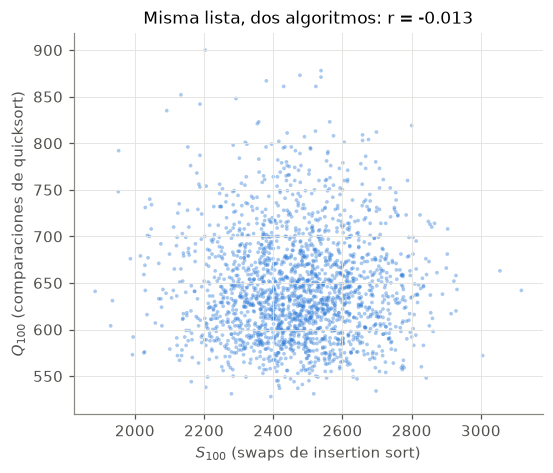

In [17]:
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ax.scatter(S, Q, s=6, alpha=0.4, color=AZUL, edgecolors="none")
ax.set_xlabel("$S_{100}$ (swaps de insertion sort)")
ax.set_ylabel("$Q_{100}$ (comparaciones de quicksort)")
ax.set_title(f"Misma lista, dos algoritmos: r = {r_SQ:.3f}")
plt.show()

La correlación entre $S_{100}$ y $Q_{100}$ es $r = -0{,}013$, prácticamente 0. Entonces $\operatorname{Cov}(S, Q) \approx 0$ y en la fórmula $\operatorname{Var}(S - Q) = \operatorname{Var}(S) + \operatorname{Var}(Q) - 2\operatorname{Cov}(S, Q)$ el término que se resta casi no aporta. Con los datos, $\operatorname{Var}(S) + \operatorname{Var}(Q) = 32088$ y $\operatorname{Var}(S - Q) = 32334$, prácticamente lo mismo.

Por lo tanto en este caso aparear no reduciría la variabilidad de la diferencia. Tiene sentido porque los dos conteos dependen de cosas distintas de la lista: $S_{100}$ es la cantidad de inversiones, y $Q_{100}$ depende de qué pivotes le tocan a quicksort en cada partición. Que una lista le cueste mucho a insertion sort no dice nada de lo que le cuesta a quicksort, como se ve en el gráfico de dispersión.

---

### 3.3 b)

Repita con las comparaciones $C_{100}$ y los swaps $S_{100}$ de insertion sort. Con $N = 10$ listas, contraste $H_0: \mathrm{E}(C_{100}) = \mathrm{E}(S_{100})$ con un test $t$ no apareado y con uno apareado (`scipy.stats.ttest_rel`). Repita $R = 1000$ veces con listas nuevas y compare la proporción de rechazos de ambos tests.

---

In [18]:
def generar_C_S(N=10, n=100):
    """Corre insertion sort sobre N listas uniformes nuevas.
    Devuelve (C, S): comparaciones y swaps, apareados por lista."""
    C, S_ = np.empty(N, dtype=int), np.empty(N, dtype=int)
    for r in range(N):
        S_[r], C[r] = insertion_sort(permutacion_aleatoria(n, rng))
    return C, S_


def t_no_apareado(x, y):
    return stats.ttest_ind(x, y, equal_var=False).pvalue


def t_apareado(x, y):
    return stats.ttest_rel(x, y).pvalue


N_ap, R_ap = 10, 1000
rech_no_ap = proporcion_rechazos(lambda: generar_C_S(N_ap), t_no_apareado, R_ap)
rech_ap = proporcion_rechazos(lambda: generar_C_S(N_ap), t_apareado, R_ap)

print(f"N = {N_ap}, R = {R_ap}")
print(f"Proporción de rechazos, t no apareado (Welch): {rech_no_ap:.3f}")
print(f"Proporción de rechazos, t apareado:            {rech_ap:.3f}")

N = 10, R = 1000
Proporción de rechazos, t no apareado (Welch): 0.034
Proporción de rechazos, t apareado:            1.000


Como referencia, la correlación entre $C_{100}$ y $S_{100}$ y las varianzas, con las 2000 listas del experimento `uniforme`.

In [19]:
C = (uniforme[uniforme["algoritmo"] == "insertion"]
     .sort_values("lista")["comparaciones"].to_numpy())

print(f"Correlación entre C_100 y S_100: r = {np.corrcoef(C, S)[0, 1]:.5f}")
print(f"Media de C = {C.mean():.1f},  media de S = {S.mean():.1f},  diferencia = {C.mean() - S.mean():.1f}")
print(f"Var(C) + Var(S)  = {C.var(ddof=1) + S.var(ddof=1):.0f}")
print(f"Var(C - S)       = {np.var(C - S, ddof=1):.2f}")

Correlación entre C_100 y S_100: r = 0.99994
Media de C = 2564.9,  media de S = 2470.1,  diferencia = 94.8
Var(C) + Var(S)  = 57633
Var(C - S)       = 3.52


En este caso $H_0$ es falsa: con las 2000 listas del experimento `uniforme` la media de $C_{100}$ es $2564{,}9$ y la de $S_{100}$ es $2470{,}1$, una diferencia de unas $95$ comparaciones. Entonces las dos proporciones de rechazos estiman potencias.

El test apareado rechaza en el $100\%$ de las repeticiones y el no apareado solo en el $3{,}4\%$. La diferencia se explica por la correlación entre $C_{100}$ y $S_{100}$, que es $r = 0{,}99994$: las dos suben y bajan juntas, porque cada swap de insertion sort viene después de una comparación. Por eso $\operatorname{Var}(C) + \operatorname{Var}(S) = 57633$, mientras que $\operatorname{Var}(C - S) = 3{,}5$.

El test apareado trabaja con las diferencias $D_i = C_i - S_i$ de cada lista, que tienen desvío $1{,}88$. Con $N = 10$ el estadístico es $T \approx \frac{94{,}8}{1{,}88/\sqrt{10}} \approx 160$, muchísimo más grande que el umbral, así que rechaza siempre.

El test no apareado trata a las dos muestras como independientes y usa como denominador $\sqrt{s_C^2/10 + s_S^2/10} \approx \sqrt{57633/10} \approx 76$. Entonces $T \approx 94{,}8/76 \approx 1{,}25$, que no llega al umbral ($\approx 2{,}1$ con estos grados de libertad). Rechaza incluso menos que el $5\%$ porque la diferencia de medias casi no varía de una repetición a otra (siempre da cerca de $95$), y solo rechaza cuando por azar las varianzas muestrales salen muy chicas.

---

### 3.3 c)

**(Optativo)** Explique la diferencia. ¿Por qué $C_{100} - S_{100}$ varía tan poco de una lista a otra? (Ayuda: en cada iteración del **para** de insertion sort, ¿cuántas comparaciones no terminan en un swap?)

---

C - S en las 2000 listas: media = 94.78, desvío = 1.88, mín = 88, máx = 99
n - 1 = 99,  H_100 = 5.19


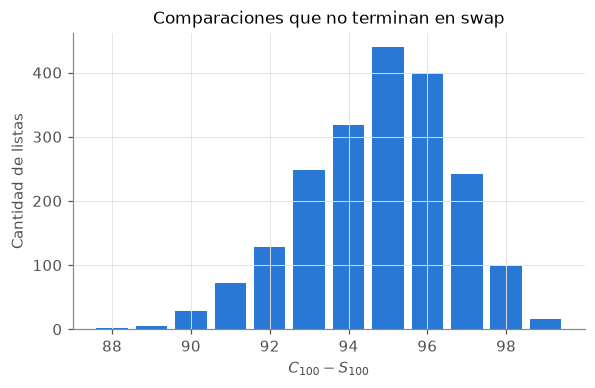

In [20]:
D = C - S
print(f"C - S en las 2000 listas: media = {D.mean():.2f}, desvío = {D.std(ddof=1):.2f}, mín = {D.min()}, máx = {D.max()}")
print(f"n - 1 = {100 - 1},  H_100 = {H:.2f}")

valores, cuentas = np.unique(D, return_counts=True)
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(valores, cuentas, color=AZUL)
ax.set_xlabel("$C_{100} - S_{100}$")
ax.set_ylabel("Cantidad de listas")
ax.set_title("Comparaciones que no terminan en swap")
plt.show()

En cada iteración del **para** de insertion sort, el **mientras** termina de una de dos formas: con una comparación que da falso y sale con el break, o porque $j$ llega a 0. En el primer caso hay exactamente una comparación que no termina en swap, y en el segundo no hay ninguna. Todas las demás comparaciones terminan en un swap.

Entonces $C_{100} - S_{100} = 99 - M$, donde $M$ es la cantidad de veces que el elemento llega hasta la posición 0. Eso pasa cuando el elemento es el más chico de todos los que vio hasta ese momento (un nuevo mínimo). En una permutación uniforme, el elemento de la posición $j$ es el mínimo de los primeros $j$ con probabilidad $1/j$, así que $\mathrm{E}(M) = \sum_{j=2}^{100} 1/j = H_{100} - 1$ y
$$\mathrm{E}(C_{100} - S_{100}) = 99 - (H_{100} - 1) = 100 - H_{100} \approx 94{,}81,$$
que coincide con la media observada de $94{,}78$.

$C_{100} - S_{100}$ varía tan poco porque solo depende de $M$, que es un número chico: la cantidad de nuevos mínimos en 100 elementos es en promedio $H_{100} - 1 \approx 4{,}2$. Con los datos, $C_{100} - S_{100}$ va de $88$ a $99$ con desvío $1{,}88$, mientras que $S_{100}$ tiene desvío $\approx 170$. Además, como esos eventos son independientes, $\operatorname{Var}(M) = \sum_{j=2}^{100} \frac{1}{j}\left(1 - \frac{1}{j}\right) = H_{100} - H^{(2)}_{100} \approx 3{,}55$, que coincide con la varianza observada de $3{,}52$.

---

## Ejercicio 3.4: ANOVA

Considere $g = 4$ grupos de listas con desorden $k = 100, 150, 200$ y $300$, con 100 listas nuevas por grupo.

### 3.4 a)

Plantee las hipótesis del ANOVA de un factor para comparar $\mathrm{E}(Q_{100} \mid k)$ entre los cuatro grupos, calcule el estadístico $F$ (`scipy.stats.f_oneway`) y concluya.

---

entre = 100 · Var(medias) = 55421
dentro = promedio de las varianzas = 4403
F = 55421 / 4403 = 12.59   (f_oneway: 12.59)
gl = (3, 396)   valor crítico = 2.63   p-valor = 7.08e-08


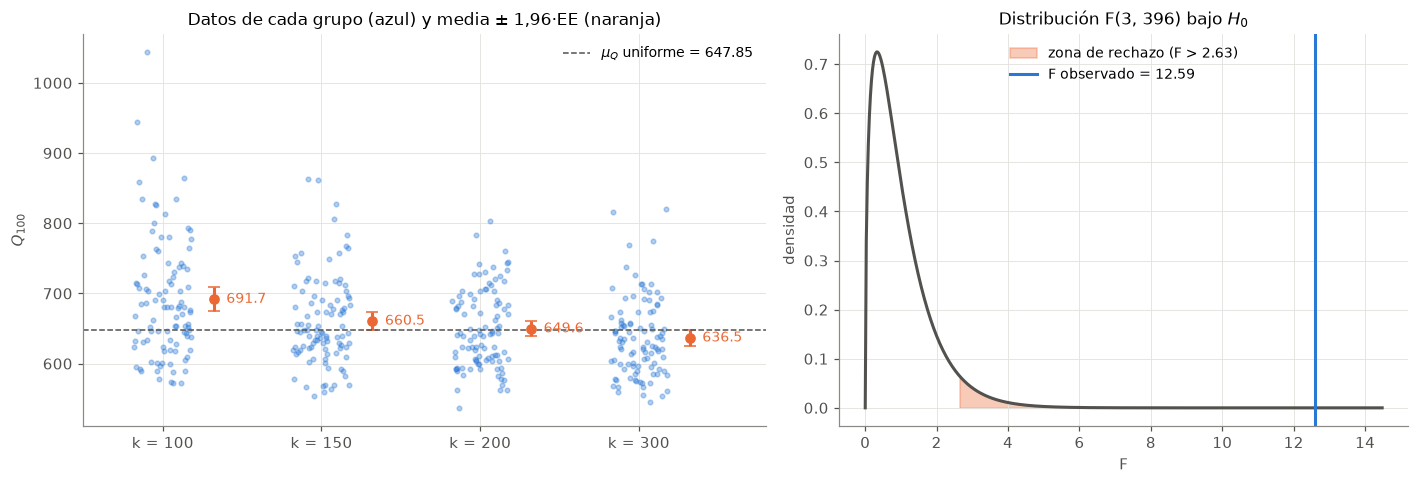

In [21]:
from itertools import combinations

ks_anova = [100, 150, 200, 300]
N_anova = 100

# 4 grupos independientes de 100 listas nuevas cada uno
grupos = {k: generar_Q(N_anova, k) for k in ks_anova}

resumen_anova = pd.DataFrame({
    "media": {k: x.mean() for k, x in grupos.items()},
    "desvío": {k: x.std(ddof=1) for k, x in grupos.items()},
}).rename_axis("k")

F, p_anova = stats.f_oneway(*grupos.values())
g, N_tot = len(grupos), sum(len(x) for x in grupos.values())
F_crit = stats.f.ppf(0.95, g - 1, N_tot - g)

# F "a mano": variabilidad entre grupos / variabilidad dentro de los grupos
entre = N_anova * resumen_anova["media"].var(ddof=1)
dentro = (resumen_anova["desvío"] ** 2).mean()
print(f"entre = {N_anova} · Var(medias) = {entre:.0f}")
print(f"dentro = promedio de las varianzas = {dentro:.0f}")
print(f"F = {entre:.0f} / {dentro:.0f} = {entre / dentro:.2f}   (f_oneway: {F:.2f})")
print(f"gl = ({g - 1}, {N_tot - g})   valor crítico = {F_crit:.2f}   p-valor = {p_anova:.2e}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={"width_ratios": [1.2, 1]})

# Izquierda: los datos de cada grupo y su media con IC 95%
rng_plot = np.random.default_rng(0)  # solo para el jitter, no toca rng
for j, (k, x) in enumerate(grupos.items()):
    jitter = rng_plot.uniform(-0.18, 0.18, size=len(x))
    ax1.plot(j + jitter, x, "o", ms=3, color=AZUL, alpha=0.35)
    ee = x.std(ddof=1) / np.sqrt(len(x))
    ax1.errorbar(j + 0.32, x.mean(), yerr=1.96 * ee, fmt="o", color=NARANJA, ms=6, capsize=4)
    ax1.annotate(f"{x.mean():.1f}", (j + 0.4, x.mean()), va="center", fontsize=9, color=NARANJA)
ax1.axhline(mu_Q, ls="--", color=GRIS, lw=1, label=f"$\\mu_Q$ uniforme = {mu_Q:.2f}")
ax1.set_xticks(range(len(grupos)), [f"k = {k}" for k in grupos])
ax1.set_xlim(-0.5, len(grupos) - 0.2)
ax1.set_ylabel("$Q_{100}$")
ax1.set_title("Datos de cada grupo (azul) y media ± 1,96·EE (naranja)")
ax1.legend(loc="upper right")

# Derecha: distribución de F bajo H0 y el F observado
xs = np.linspace(0, max(F, F_crit) * 1.15, 500)
ax2.plot(xs, stats.f.pdf(xs, g - 1, N_tot - g), color=GRIS)
ax2.fill_between(xs, stats.f.pdf(xs, g - 1, N_tot - g), where=xs >= F_crit, color=NARANJA, alpha=0.35,
                 label=f"zona de rechazo (F > {F_crit:.2f})")
ax2.axvline(F, color=AZUL, lw=2, label=f"F observado = {F:.2f}")
ax2.set_xlabel("F")
ax2.set_ylabel("densidad")
ax2.set_title(f"Distribución F({g - 1}, {N_tot - g}) bajo $H_0$")
ax2.legend()
plt.tight_layout()
plt.show()

Las hipótesis son $H_0: \mu_{100} = \mu_{150} = \mu_{200} = \mu_{300}$, donde $\mu_k = \mathrm{E}(Q_{100} \mid k)$, contra $H_1$: al menos una de las medias es distinta. $H_1$ no dice que sean todas distintas, alcanza con que una lo sea.

El estadístico $F$ es el cociente entre la variabilidad entre grupos y la variabilidad dentro de los grupos. El denominador promedia las varianzas de los cuatro grupos ($\approx 4403$), lo cual estima $\sigma^2$, la varianza de $Q_{100}$ dentro de un grupo. El numerador es $100$ por la varianza de las cuatro medias ($100 \cdot 554 \approx 55\,420$). Como la media de 100 listas tiene varianza $\sigma^2/100$, si $H_0$ fuera verdadera las medias variarían solo por azar, el numerador también estimaría $\sigma^2$ y $F$ quedaría cerca de 1.

Obtuvimos $F = 12{,}59$, con $(3, 396)$ grados de libertad. Bajo $H_0$ el valor crítico al nivel $0{,}05$ es $2{,}63$ y el p-valor da $7 \cdot 10^{-8}$, así que rechazamos $H_0$. Lo cual significa que la media de $Q_{100}$ depende de $k$: las medias de los grupos se separan unas 12 veces más de lo que explicaría el azar.

Tiene sentido porque con menos transposiciones la lista queda más ordenada y quicksort con pivote en el primer elemento hace más comparaciones. Las medias bajan de $691{,}7$ con $k = 100$ a $660{,}5$, $649{,}6$ y $636{,}5$, y las dos últimas ya quedan cerca de $\mu_Q = 647{,}85$.

---

### 3.4 b)

¿Se cumplen los supuestos del ANOVA? Compare los desvíos de los grupos y describa la forma de cada distribución.

---

desvíos: k=100: 86.1, k=150: 63.7, k=200: 55.5, k=300: 55.4
cociente desvío máximo / mínimo = 1.55
Levene (H0: varianzas iguales): p-valor = 1.95e-03


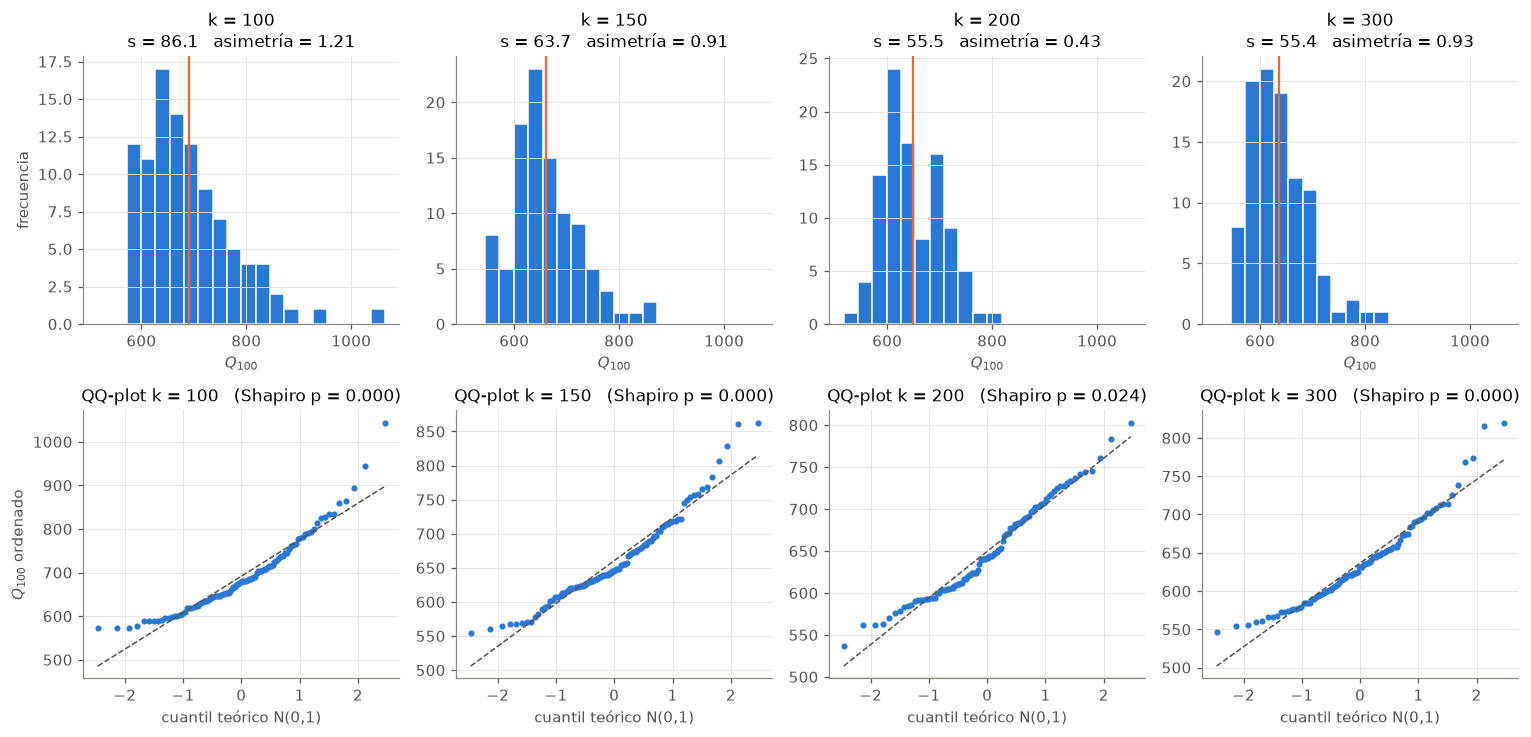

In [22]:
desvios = resumen_anova["desvío"]
print(f"desvíos: " + ", ".join(f"k={k}: {s:.1f}" for k, s in desvios.items()))
print(f"cociente desvío máximo / mínimo = {desvios.max() / desvios.min():.2f}")
print(f"Levene (H0: varianzas iguales): p-valor = {stats.levene(*grupos.values()).pvalue:.2e}")

# Histogramas (arriba) y QQ-plots (abajo) de cada grupo
fig, axes = plt.subplots(2, 4, figsize=(14, 6.8))
lim = (min(x.min() for x in grupos.values()) - 20, max(x.max() for x in grupos.values()) + 20)
for j, (k, x) in enumerate(grupos.items()):
    ax = axes[0, j]
    ax.hist(x, bins=20, range=lim, color=AZUL, edgecolor="white")
    ax.axvline(x.mean(), color=NARANJA, lw=1.5)
    ax.set_title(f"k = {k}\ns = {x.std(ddof=1):.1f}   asimetría = {stats.skew(x):.2f}")
    ax.set_xlabel("$Q_{100}$")

    ax = axes[1, j]
    (m, xo), (pend, ord_, r) = stats.probplot(x, dist="norm")
    ax.plot(m, xo, "o", ms=3, color=AZUL)
    ax.plot(m, ord_ + pend * m, "--", color=GRIS, lw=1)
    ax.set_title(f"QQ-plot k = {k}   (Shapiro p = {stats.shapiro(x).pvalue:.3f})")
    ax.set_xlabel("cuantil teórico N(0,1)")
axes[0, 0].set_ylabel("frecuencia")
axes[1, 0].set_ylabel("$Q_{100}$ ordenado")
plt.tight_layout()
plt.show()

Los supuestos del ANOVA son que los grupos sean independientes, que los datos de cada grupo sean normales y que todos los grupos tengan la misma varianza. Este último hace falta porque el denominador de $F$ promedia las varianzas de los grupos suponiendo que todas estiman el mismo $\sigma^2$. La independencia se cumple porque cada grupo usa listas nuevas.

La igualdad de varianzas no se cumple. El desvío baja de $86{,}1$ con $k = 100$ a $63{,}7$ con $k = 150$ y $\approx 55{,}4$ con $k = 200$ y $300$, un cociente de $1{,}55$ entre el mayor y el menor, y el test de Levene, cuya $H_0$ es que las varianzas son iguales, rechaza con p-valor $0{,}002$. Tiene sentido porque con poco desorden $Q_{100}$ no solo tiene más media sino también más dispersión: en el experimento `desorden` el desvío pasa de $131$ con $k = 50$ a $74$ con $k = 100$ y a $\approx 60$ para $k$ grandes, que es el de las permutaciones uniformes.

La normalidad tampoco se cumple. Las cuatro distribuciones son asimétricas a derecha (asimetrías $1{,}21$, $0{,}91$, $0{,}43$ y $0{,}93$), con una cola larga hacia valores altos: con $k = 100$ hay listas con más de 1000 comparaciones mientras que la media es 692. En los QQ-plots los puntos se curvan hacia arriba a la derecha, y Shapiro–Wilk rechaza en los cuatro grupos. Es la misma forma que vimos para $Q_{100}$ en el 3.1.

Por otro lado, el ANOVA compara medias, y con 100 listas por grupo las medias son aproximadamente normales por el TCL aunque los datos no lo sean. Además los cuatro grupos tienen el mismo tamaño, y en ese caso varianzas distintas afectan poco al nivel del test. Con un p-valor de $7 \cdot 10^{-8}$ la conclusión del a) no cambia, pero para las comparaciones de a pares conviene usar Welch, que no supone varianzas iguales.

---

### 3.4 c)

Haga las 6 comparaciones de a pares con tests de Welch (que no suponen varianzas iguales) y corrección de Bonferroni. ¿Qué grupos difieren? ¿Es posible que el ANOVA rechace y ninguna comparación de a pares resulte significativa? ¿Por qué?

---

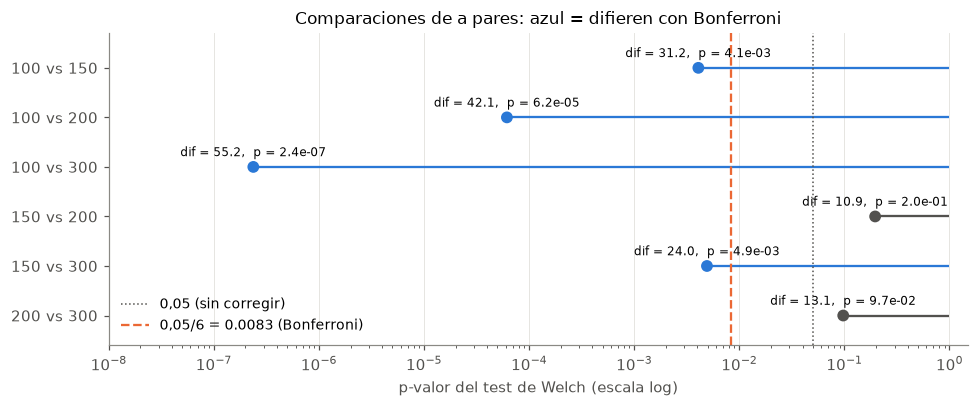

In [23]:
m_pares = len(list(combinations(ks_anova, 2)))
alfa_bonf = 0.05 / m_pares

filas = []
for k1, k2 in combinations(ks_anova, 2):
    x, y = grupos[k1], grupos[k2]
    filas.append({"par": f"{k1} vs {k2}", "dif": x.mean() - y.mean(),
                  "p": stats.ttest_ind(x, y, equal_var=False).pvalue})
pares = pd.DataFrame(filas).set_index("par")
pares["difieren"] = pares["p"] < alfa_bonf

fig, ax = plt.subplots(figsize=(9, 3.8))
y = np.arange(len(pares))[::-1]
colores = [AZUL if d else GRIS for d in pares["difieren"]]
ax.hlines(y, pares["p"], 1, color=colores, lw=1.5)
ax.scatter(pares["p"], y, color=colores, s=45, zorder=3)
for yi, (par, fila) in zip(y, pares.iterrows()):
    ax.annotate(f"dif = {fila['dif']:.1f},  p = {fila['p']:.1e}", (fila["p"], yi),
                xytext=(0, 7), textcoords="offset points", ha="center", fontsize=8)
ax.axvline(0.05, color=GRIS, ls=":", lw=1, label="0,05 (sin corregir)")
ax.axvline(alfa_bonf, color=NARANJA, ls="--", lw=1.5, label=f"0,05/{m_pares} = {alfa_bonf:.4f} (Bonferroni)")
ax.set_xscale("log")
ax.set_xlim(1e-8, 1.5)
ax.set_ylim(-0.6, len(pares) - 0.3)
ax.set_yticks(y, pares.index)
ax.set_xlabel("p-valor del test de Welch (escala log)")
ax.set_title("Comparaciones de a pares: azul = difieren con Bonferroni")
ax.legend(loc="lower left")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

Si hiciéramos los 6 tests al nivel $0{,}05$, la probabilidad de rechazar por error en alguno sería mucho mayor que $0{,}05$ (si fueran independientes, $1 - 0{,}95^6 \approx 0{,}26$). La corrección de Bonferroni hace cada test al nivel $0{,}05/6 \approx 0{,}0083$, así la probabilidad de algún falso rechazo queda como mucho en $0{,}05$.

El grupo $k = 100$ difiere de los otros tres (p-valores entre $0{,}004$ y $2 \cdot 10^{-7}$), y además difieren $k = 150$ y $k = 300$ ($p = 0{,}005$). No encontramos diferencias entre $150$ y $200$ ($p = 0{,}196$) ni entre $200$ y $300$ ($p = 0{,}098$).

Esto parece contradictorio, porque si $150 = 200$ y $200 = 300$ tendría que ser $150 = 300$. Pero no rechazar no significa que las medias sean iguales, sino que con 100 listas por grupo el test no alcanza a detectar diferencias de 11 y 13 comparaciones, mientras que una de 24 sí. Es lo mismo que pasaba en el 3.2 c.

Sí es posible que el ANOVA rechace y ninguna comparación de a pares resulte significativa. El ANOVA es un único test al nivel $0{,}05$ que usa los 400 datos, mientras que cada comparación usa solo dos grupos y se hace al nivel $0{,}0083$, que es mucho más exigente. Además, si las cuatro medias están todas un poco separadas, ninguna diferencia sola alcanza, pero en el numerador de $F$ se suman todas y $F$ puede dar grande. En nuestro caso no pasa porque $k = 100$ está muy lejos del resto.

---

## Ejercicio 3.5: Bootstrap

La mediana de $Q_{100}$ no tiene una fórmula sencilla. Sea $\delta$ la diferencia entre la mediana de las comparaciones de quicksort con desorden $k = 100$ y la mediana sobre permutaciones uniformes.

### 3.5 a)

Con $N = 50$ listas de cada tipo, construya un intervalo bootstrap percentil de nivel 0,95 para $\delta$, remuestreando cada grupo por separado ($B = 1000$).

---

mediana k=100 = 663.5   mediana uniforme = 652.0
delta estimado = 11.5
IC bootstrap percentil 95% para delta: [-13.5, 41.5]
con scipy.stats.bootstrap:            [-12.0, 44.0]

referencia: mediana uniforme (2000 listas) = 636, mediana k=100 (300 listas) = 661  ->  delta ≈ 25


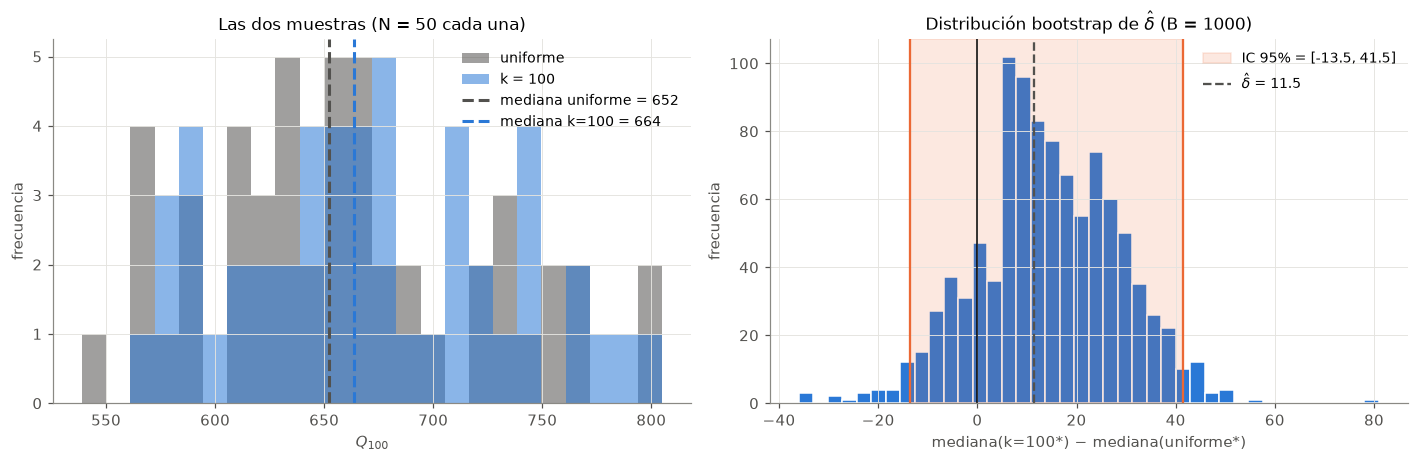

In [24]:
def ic_bootstrap_dif(x, y, estadistico, B=1000):
    """IC bootstrap percentil 95% para estadistico(x) - estadistico(y).
    Remuestrea cada grupo por separado: B muestras de tamaño len(x) con reposición de x,
    y lo mismo con y. Devuelve el intervalo y los B valores bootstrap."""
    bx = rng.choice(x, size=(B, len(x)), replace=True)
    by = rng.choice(y, size=(B, len(y)), replace=True)
    difs = estadistico(bx, axis=1) - estadistico(by, axis=1)
    return np.percentile(difs, [2.5, 97.5]), difs

N_boot, B = 50, 1000
x_unif = generar_Q(N_boot)        # permutaciones uniformes
x_100 = generar_Q(N_boot, 100)    # desorden k = 100

delta_hat = np.median(x_100) - np.median(x_unif)
(ic_inf, ic_sup), difs_med = ic_bootstrap_dif(x_100, x_unif, np.median, B)

print(f"mediana k=100 = {np.median(x_100):.1f}   mediana uniforme = {np.median(x_unif):.1f}")
print(f"delta estimado = {delta_hat:.1f}")
print(f"IC bootstrap percentil 95% para delta: [{ic_inf:.1f}, {ic_sup:.1f}]")

# Mismo intervalo con scipy (otros remuestreos, así que da parecido pero no idéntico)
res = stats.bootstrap((x_100, x_unif),
                      lambda a, b, axis: np.median(a, axis=axis) - np.median(b, axis=axis),
                      method="percentile", n_resamples=B, rng=rng)
print(f"con scipy.stats.bootstrap:            [{res.confidence_interval.low:.1f}, {res.confidence_interval.high:.1f}]")

# Referencia con muchas listas (conteos.jsonl): el delta "verdadero" aproximado
q_ref = df[df["algoritmo"] == "quick_primero"]
med_u_ref = q_ref[q_ref["experimento"] == "uniforme"]["comparaciones"].median()
med_k_ref = q_ref[(q_ref["experimento"] == "desorden") & (q_ref["k"] == 100)]["comparaciones"].median()
print(f"\nreferencia: mediana uniforme (2000 listas) = {med_u_ref:.0f}, "
      f"mediana k=100 (300 listas) = {med_k_ref:.0f}  ->  delta ≈ {med_k_ref - med_u_ref:.0f}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.3))

# Izquierda: las dos muestras
bins = np.linspace(min(x_unif.min(), x_100.min()), max(x_unif.max(), x_100.max()), 25)
ax1.hist(x_unif, bins=bins, color=GRIS, alpha=0.55, label="uniforme")
ax1.hist(x_100, bins=bins, color=AZUL, alpha=0.55, label="k = 100")
ax1.axvline(np.median(x_unif), color=GRIS, lw=2, ls="--", label=f"mediana uniforme = {np.median(x_unif):.0f}")
ax1.axvline(np.median(x_100), color=AZUL, lw=2, ls="--", label=f"mediana k=100 = {np.median(x_100):.0f}")
ax1.set_xlabel("$Q_{100}$")
ax1.set_ylabel("frecuencia")
ax1.set_title(f"Las dos muestras (N = {N_boot} cada una)")
ax1.legend()

# Derecha: los B valores bootstrap de la diferencia de medianas
ax2.hist(difs_med, bins=40, color=AZUL, edgecolor="white")
ax2.axvspan(ic_inf, ic_sup, color=NARANJA, alpha=0.15, label=f"IC 95% = [{ic_inf:.1f}, {ic_sup:.1f}]")
for v in (ic_inf, ic_sup):
    ax2.axvline(v, color=NARANJA, lw=1.5)
ax2.axvline(delta_hat, color=GRIS, lw=1.5, ls="--", label=f"$\\hat\\delta$ = {delta_hat:.1f}")
ax2.axvline(0, color="black", lw=1)
ax2.set_xlabel("mediana(k=100*) − mediana(uniforme*)")
ax2.set_ylabel("frecuencia")
ax2.set_title(f"Distribución bootstrap de $\\hat\\delta$ (B = {B})")
ax2.legend()
plt.tight_layout()
plt.show()

Con $N = 50$ listas de cada tipo obtuvimos una mediana de $663{,}5$ comparaciones con $k = 100$ y de $652$ con permutaciones uniformes, así que $\hat\delta = 11{,}5$.

Para el intervalo bootstrap remuestreamos cada grupo por separado: tomamos 50 valores con reposición de la muestra con $k = 100$ y 50 de la muestra uniforme, calculamos la diferencia de medianas, y repetimos esto $B = 1000$ veces. Cada muestra bootstrap hace de muestra nueva usando la muestra original en lugar de la distribución verdadera, que no conocemos, así que la dispersión de esas 1000 diferencias aproxima cuánto variaría $\hat\delta$ de una muestra a otra. El intervalo va del percentil 2,5 al 97,5 de esas diferencias, y nos dio $[-13{,}5;\ 41{,}5]$. Con `scipy.stats.bootstrap` da $[-12;\ 44]$, que es parecido pero no igual porque los remuestreos son otros.

El intervalo contiene al 0, así que con estas 50 listas no podemos decir que las medianas sean distintas. Por otro lado, con las listas de `conteos.jsonl` la mediana uniforme es $636$ y la de $k = 100$ es $661$, así que $\delta \approx 25$. El intervalo mide 55 comparaciones, mucho más que esa diferencia, por lo que con $N = 50$ es fácil que no la detecte.

---

### 3.5 b)

Si el intervalo no contiene al 0, ¿qué se puede concluir? Repitiendo la construcción $R = 200$ veces con muestras nuevas, estime con qué frecuencia el intervalo excluye al 0. Haga lo mismo con un intervalo bootstrap para la diferencia de *medias*, y compare las dos frecuencias con la proporción de rechazos del test de Welch para $k = 100$ del ítem 3.2. ¿Por qué el intervalo basado en medianas excluye al 0 con menos frecuencia?

---

       mediana: proporción = 0.300  (± 0.064)
         media: proporción = 0.595  (± 0.068)
 Welch (3.2 b): proporción = 0.563  (± 0.056)

IC para la diferencia de medianas: ancho promedio = 66.0, centro promedio = 24.4
IC para la diferencia de medias: ancho promedio = 54.0, centro promedio = 29.8


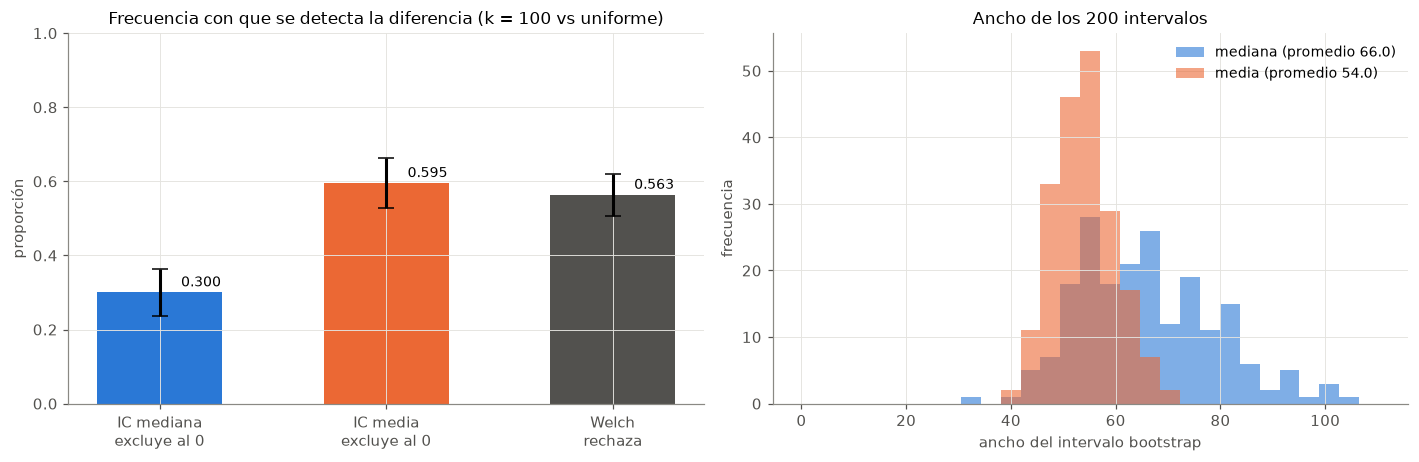

In [25]:
R_boot = 200
excluye = {"mediana": [], "media": []}
anchos = {"mediana": [], "media": []}
centros = {"mediana": [], "media": []}

for _ in range(R_boot):
    x_u, x_k = generar_Q(N_boot), generar_Q(N_boot, 100)   # las mismas muestras para los dos intervalos
    for nombre, f in [("mediana", np.median), ("media", np.mean)]:
        (inf, sup), _ = ic_bootstrap_dif(x_k, x_u, f, B)
        excluye[nombre].append(inf > 0 or sup < 0)
        anchos[nombre].append(sup - inf)
        centros[nombre].append((inf + sup) / 2)

frec = {nombre: np.mean(v) for nombre, v in excluye.items()}
frec["Welch (3.2 b)"] = potencia[100]
R_de = {"mediana": R_boot, "media": R_boot, "Welch (3.2 b)": R}

for nombre, p in frec.items():
    ee = np.sqrt(p * (1 - p) / R_de[nombre])
    print(f"{nombre:>14}: proporción = {p:.3f}  (± {1.96 * ee:.3f})")
print()
for nombre in ("mediana", "media"):
    print(f"IC para la diferencia de {nombre}s: ancho promedio = {np.mean(anchos[nombre]):.1f}, "
          f"centro promedio = {np.mean(centros[nombre]):.1f}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.3))

# Izquierda: frecuencia con que se detecta la diferencia
nombres = list(frec)
vals = [frec[n] for n in nombres]
errs = [1.96 * np.sqrt(frec[n] * (1 - frec[n]) / R_de[n]) for n in nombres]
ax1.bar(nombres, vals, yerr=errs, capsize=5, color=[AZUL, NARANJA, GRIS], width=0.55)
for i, v in enumerate(vals):
    ax1.annotate(f"{v:.3f}", (i, v), xytext=(14, 4), textcoords="offset points", fontsize=9)
ax1.set_ylim(0, 1)
ax1.set_ylabel("proporción")
ax1.set_title("Frecuencia con que se detecta la diferencia (k = 100 vs uniforme)")
ax1.set_xticks(range(3), ["IC mediana\nexcluye al 0", "IC media\nexcluye al 0", "Welch\nrechaza"])

# Derecha: anchos de los intervalos
bins = np.linspace(0, max(max(anchos["mediana"]), max(anchos["media"])) * 1.05, 30)
ax2.hist(anchos["mediana"], bins=bins, color=AZUL, alpha=0.6, label=f"mediana (promedio {np.mean(anchos['mediana']):.1f})")
ax2.hist(anchos["media"], bins=bins, color=NARANJA, alpha=0.6, label=f"media (promedio {np.mean(anchos['media']):.1f})")
ax2.set_xlabel("ancho del intervalo bootstrap")
ax2.set_ylabel("frecuencia")
ax2.set_title(f"Ancho de los {R_boot} intervalos")
ax2.legend()
plt.tight_layout()
plt.show()

Si el intervalo no contiene al 0 podemos concluir, con nivel $0{,}95$, que $\delta \neq 0$, es decir que la mediana de $Q_{100}$ con $k = 100$ es distinta de la de permutaciones uniformes. Es equivalente a rechazar $H_0: \delta = 0$ al nivel $0{,}05$. Si lo contiene no podemos concluir que $\delta = 0$, solo que con esos datos no se detecta la diferencia.

Como $\delta \neq 0$, la frecuencia con que el intervalo excluye al 0 estima la potencia de ese test. Repitiendo $R = 200$ veces con muestras nuevas, el intervalo para la diferencia de medianas excluyó al 0 en el $30\%$ de los casos y el intervalo para la diferencia de medias en el $59{,}5\%$, mientras que el test de Welch con $k = 100$ del 3.2 rechazó en el $56{,}3\%$. Las dos últimas son compatibles entre sí, lo cual tiene sentido porque las dos se basan en la diferencia de medias.

El intervalo basado en medianas excluye al 0 con menos frecuencia por dos razones. La primera es que es más ancho: en promedio mide $66$, contra $54$ el de medias. La mediana solo depende de los valores del medio de la muestra, así que varía más de una muestra a otra que la media.

La segunda es que la diferencia de medianas es más chica que la de medias: en promedio los intervalos están centrados en $24{,}4$ y en $29{,}8$. Tiene sentido porque con $k = 100$ la distribución tiene una cola derecha más larga que con permutaciones uniformes (en `conteos.jsonl` la mediana sube 25 comparaciones pero el percentil 90 sube 41), y las listas con muchas comparaciones suben la media pero casi no mueven la mediana.

Con un intervalo más ancho y centrado más cerca del 0, es más probable que lo contenga.